# DX602 Final Project: Bike-Sharing Demand Analysis

**Dataset Selected:** Option 3 — Outdoor Recreation (`bikes_final.csv`)

---

## Section 1: Introduction

For this project, I selected **Option 3: Outdoor Recreation (`bikes_final.csv`)**, an hourly bike-sharing dataset with **10,886 observations** from 2011–2012. *(Note: `bike_metadata.xlsx` was not included in the project folder, so variable meanings are verified from the data itself in Sections 2–3.)*

### Purpose
Understand what drives hourly bike rental demand (`count`), compare casual vs. registered riders, and test whether linear regression can explain rental volume from weather and calendar features.

### Questions to Investigate
1. How do rentals vary by season, weather, weekday, and working-day status?
2. How did demand change from 2011 to 2012, and how does it track temperature over time?
3. When do casual riders make up a larger share of trips?
4. How well does temperature (alone and with other features) predict hourly rentals using linear regression?

## Section 2: Load and Inspect the Data

Import libraries used in class (`numpy`, `pandas`, `matplotlib`) plus `sklearn` for the required regression section. Then load the CSV and inspect shape, types, sample rows, and missing values.

In [1]:
# Shared imports (same style as Weeks 10–11 homework)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

plt.close("all")

# Load the bike-sharing dataset
df_raw = pd.read_csv("bikes_final.csv")

print("Dataset shape:", df_raw.shape)
df_raw.head()

Dataset shape: (10886, 13)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day_of_week
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,Saturday
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,Saturday
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,Saturday
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,Saturday
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,Saturday


In [2]:
# Inspect structure, data types, and missing values
display(df_raw.tail())
print("\n--- DataFrame Info ---")
df_raw.info()
print("\n--- Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Unique Values per Column ---")
print(df_raw.nunique())

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day_of_week
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,Wednesday
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,Wednesday
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,Wednesday
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129,Wednesday
10885,2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88,Wednesday



--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   datetime     10886 non-null  str    
 1   season       10886 non-null  int64  
 2   holiday      10886 non-null  int64  
 3   workingday   10886 non-null  int64  
 4   weather      10886 non-null  int64  
 5   temp         10886 non-null  float64
 6   atemp        10886 non-null  float64
 7   humidity     10886 non-null  int64  
 8   windspeed    10886 non-null  float64
 9   casual       10886 non-null  int64  
 10  registered   10886 non-null  int64  
 11  count        10886 non-null  int64  
 12  day_of_week  10886 non-null  str    
dtypes: float64(3), int64(8), str(2)
memory usage: 1.1 MB

--- Missing Values ---
datetime       0
season         0
holiday        0
workingday     0
weather        0
temp           0
atemp          0
humidity       0
windspeed      0
casual       

### Initial Inspection Takeaways
* **10,886 rows × 13 columns**, with **zero missing values**.
* `datetime` is stored as text and needs to be converted to datetime.
* Numerical columns: `temp`, `atemp`, `humidity`, `windspeed`, `casual`, `registered`, `count`.
* Categorical-style columns: `season`, `holiday`, `workingday`, `weather`, `day_of_week`.

## Section 3: Data Cleaning and Preparation

Check duplicates and the identity `count == casual + registered`, parse dates, create year/month/hour columns, map numeric codes to readable labels with `.map()`, and classify day type with a small helper function.

In [3]:
def inspect_data_quality(df):
    """Run basic integrity checks on the raw bike-sharing data."""
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Duplicate timestamps:", df["datetime"].duplicated().sum())
    print("count == casual + registered everywhere:",
          (df["count"] == df["casual"] + df["registered"]).all())
    print("Zero windspeed readings:", (df["windspeed"] == 0).sum())
    print("\nWeather code counts:")
    print(df["weather"].value_counts().sort_index())


inspect_data_quality(df_raw)

Exact duplicate rows: 0
Duplicate timestamps: 0
count == casual + registered everywhere: True
Zero windspeed readings: 1313

Weather code counts:
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


In [4]:
# Cleaned working copy
df_bikes = df_raw.copy()
df_bikes["datetime"] = pd.to_datetime(df_bikes["datetime"])
df_bikes = df_bikes.sort_values("datetime").reset_index(drop=True)

# Calendar columns (Week 10 style datetime extraction)
df_bikes["year"] = df_bikes["datetime"].dt.year
df_bikes["month"] = df_bikes["datetime"].dt.month
df_bikes["day"] = df_bikes["datetime"].dt.day
df_bikes["hour"] = df_bikes["datetime"].dt.hour
# Simple YYYY-MM string for monthly plots (instead of .to_period)
df_bikes["year_month"] = (
    df_bikes["year"].astype(str) + "-" + df_bikes["month"].astype(str).str.zfill(2)
)

print("Date range:", df_bikes["datetime"].min(), "to", df_bikes["datetime"].max())
print("Days per month (min/max):",
      df_bikes.groupby(["year", "month"])["day"].nunique().min(), "/",
      df_bikes.groupby(["year", "month"])["day"].nunique().max())

# Check which months and temperatures belong to each season code
season_check = df_bikes.groupby("season").agg(
    months=("month", lambda s: sorted(s.unique().tolist())),
    avg_temp_c=("temp", "mean"),
    avg_count=("count", "mean"),
    rows=("count", "size"),
)
season_check

Date range: 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Days per month (min/max): 19 / 19


,months,avg_temp_c,avg_count,rows
season,,,,
1,"[1, 2, 3]",12.530491,116.343261,2686
2,"[4, 5, 6]",22.823483,215.251372,2733
3,"[7, 8, 9]",28.789111,234.417124,2733
4,"[10, 11, 12]",16.649239,198.988296,2734


In [5]:
# Map numeric codes to readable string labels with .map()
season_map = {
    1: "Q1: Winter (Jan-Mar)",
    2: "Q2: Spring (Apr-Jun)",
    3: "Q3: Summer (Jul-Sep)",
    4: "Q4: Fall (Oct-Dec)",
}
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Snow / Rain",
    4: "Heavy Rain / Snow",
}

df_bikes["season_label"] = df_bikes["season"].map(season_map)
df_bikes["weather_label"] = df_bikes["weather"].map(weather_map)


def classify_day_type(row):
    """Classify each row as Working Day, Weekend, or Holiday."""
    if row["holiday"] == 1:
        return "Holiday"
    elif row["workingday"] == 1:
        return "Working Day"
    return "Weekend"


df_bikes["day_type"] = df_bikes.apply(classify_day_type, axis=1)

# Fixed display orders used later with .reindex(...)
season_order = list(season_map.values())
weather_order = list(weather_map.values())
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_type_order = ["Working Day", "Weekend", "Holiday"]

df_bikes[
    ["datetime", "season_label", "weather_label", "day_type", "day_of_week",
     "temp", "humidity", "windspeed", "casual", "registered", "count"]
].head()

,datetime,season_label,weather_label,day_type,day_of_week,temp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,81,0.0,3,13,16
1,2011-01-01 01:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.02,80,0.0,8,32,40
2,2011-01-01 02:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.02,80,0.0,5,27,32
3,2011-01-01 03:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,75,0.0,3,10,13
4,2011-01-01 04:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,75,0.0,0,1,1


### Data Cleaning Summary
* No missing values or duplicate rows; `count == casual + registered` holds for every row.
* Every month from Jan 2011–Dec 2012 includes only days **1–19**.
* Season codes match meteorological quarters: 1 = Jan–Mar (coldest), 2 = Apr–Jun, 3 = Jul–Sep (warmest), 4 = Oct–Dec.
* `windspeed = 0` appears in **1,313 rows (12.06%)**; `weather = 4` appears only once.

## Section 4: Descriptive Statistics

Use `describe()` for numerical columns (Week 10) and `value_counts()` for categorical columns. A small helper prints category summaries so the same pattern can be reused.

In [6]:
def summarize_categorical(df, columns):
    """Print count and percent for each categorical column."""
    for col in columns:
        counts = df[col].value_counts()
        pcts = (df[col].value_counts(normalize=True) * 100).round(2)
        summary = pd.DataFrame({"count": counts, "percent (%)": pcts})
        print(f"\n=== {col} ===")
        display(summary)


numeric_cols = ["temp", "atemp", "humidity", "windspeed", "casual", "registered", "count"]
categorical_cols = ["season_label", "weather_label", "day_type", "day_of_week", "year"]

# describe() already gives count, mean, std, min, 25%, 50%, 75%, max
print("--- Numerical Summary (describe) ---")
display(df_bikes[numeric_cols].describe().round(2))

# IQR = 75% - 25%
iqr = (df_bikes[numeric_cols].quantile(0.75) - df_bikes[numeric_cols].quantile(0.25)).round(2)
print("\n--- IQR (75% - 25%) ---")
display(iqr.to_frame("IQR"))

summarize_categorical(df_bikes, categorical_cols)

--- Numerical Summary (describe) ---


,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.00,10886.00,10886.00,10886.00,10886.00,10886.00,10886.00
mean,20.23,23.66,61.89,12.80,36.02,155.55,191.57
std,7.79,8.47,19.25,8.16,49.96,151.04,181.14
min,0.82,0.76,0.00,0.00,0.00,0.00,1.00
25%,13.94,16.66,47.00,7.00,4.00,36.00,42.00
50%,20.50,24.24,62.00,13.00,17.00,118.00,145.00
75%,26.24,31.06,77.00,17.00,49.00,222.00,284.00
max,41.00,45.46,100.00,57.00,367.00,886.00,977.00



--- IQR (75% - 25%) ---


,IQR
temp,12.3
atemp,14.4
humidity,30.0
windspeed,10.0
casual,45.0
registered,186.0
count,242.0



=== season_label ===


,count,percent (%)
season_label,,
Q4: Fall (Oct-Dec),2734,25.11
Q2: Spring (Apr-Jun),2733,25.11
Q3: Summer (Jul-Sep),2733,25.11
Q1: Winter (Jan-Mar),2686,24.67


... (4 outputs left out)


=== day_of_week ===


,count,percent (%)
day_of_week,,
Saturday,1584,14.55
Sunday,1579,14.50
Thursday,1553,14.27
Monday,1551,14.25
Wednesday,1551,14.25
Tuesday,1539,14.14
Friday,1529,14.05



=== year ===


,count,percent (%)
year,,
2012,5464,50.19
2011,5422,49.81


### Descriptive Statistics Insights
* Mean hourly rentals are **191.57**, but the median is **145**, so demand is right-skewed (quiet nights vs. rush-hour peaks up to **977**).
* Registered riders average **155.55/hr** vs. casual **36.02/hr**.
* Temperature averages **20.23°C**; about **66%** of hours are Clear/Partly Cloudy.
* Seasons, years, and weekdays are evenly represented.

## Section 5: Numerical Data Visualizations

Histograms, box plots, and a bar chart of average rentals by hour of day.

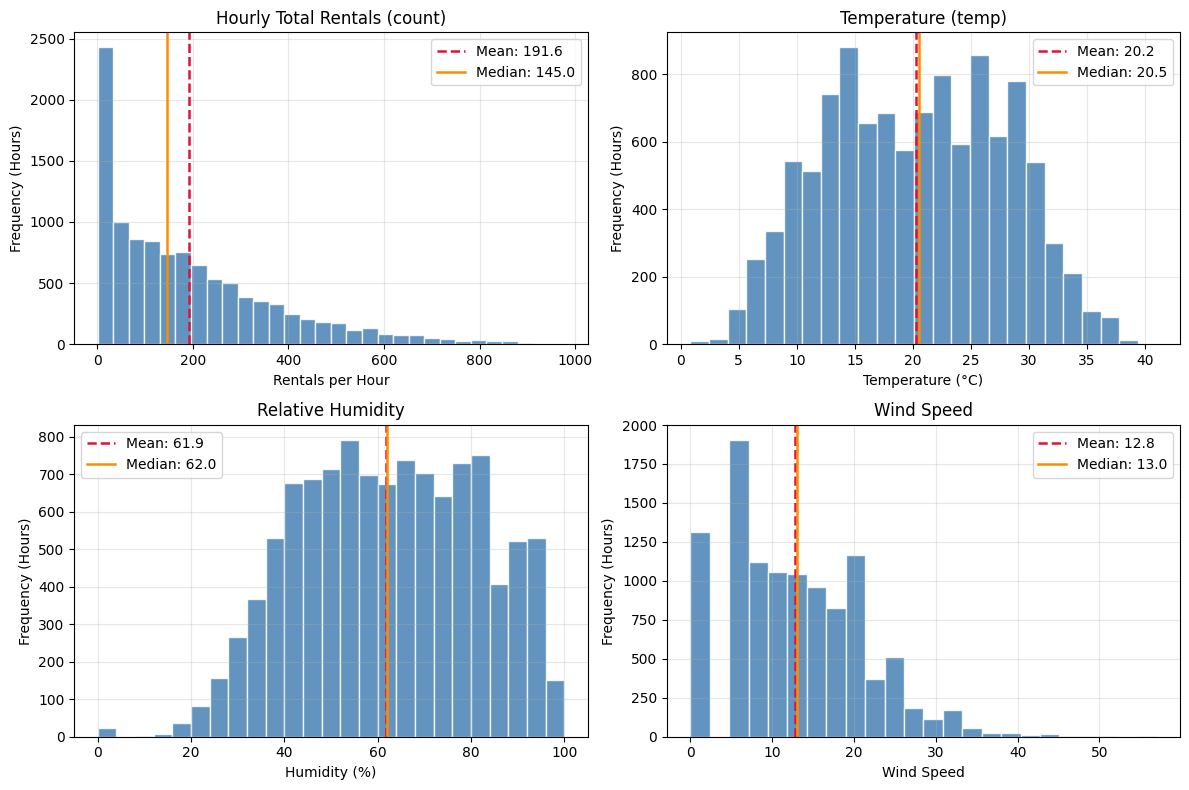

In [7]:
def plot_histogram_grid(df, columns, titles, xlabels, bins_list):
    """Plot histograms with mean and median lines using a reusable loop."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for i, col in enumerate(columns):
        ax = axes[i]
        data = df[col]
        ax.hist(data, bins=bins_list[i], color="steelblue", edgecolor="white", alpha=0.85)
        ax.axvline(data.mean(), color="crimson", linestyle="--", linewidth=1.8,
                   label=f"Mean: {data.mean():.1f}")
        ax.axvline(data.median(), color="darkorange", linestyle="-", linewidth=1.8,
                   label=f"Median: {data.median():.1f}")
        ax.set_title(titles[i])
        ax.set_xlabel(xlabels[i])
        ax.set_ylabel("Frequency (Hours)")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()


plot_histogram_grid(
    df_bikes,
    columns=["count", "temp", "humidity", "windspeed"],
    titles=[
        "Hourly Total Rentals (count)",
        "Temperature (temp)",
        "Relative Humidity",
        "Wind Speed",
    ],
    xlabels=["Rentals per Hour", "Temperature (°C)", "Humidity (%)", "Wind Speed"],
    bins_list=[30, 25, 25, 24],
)

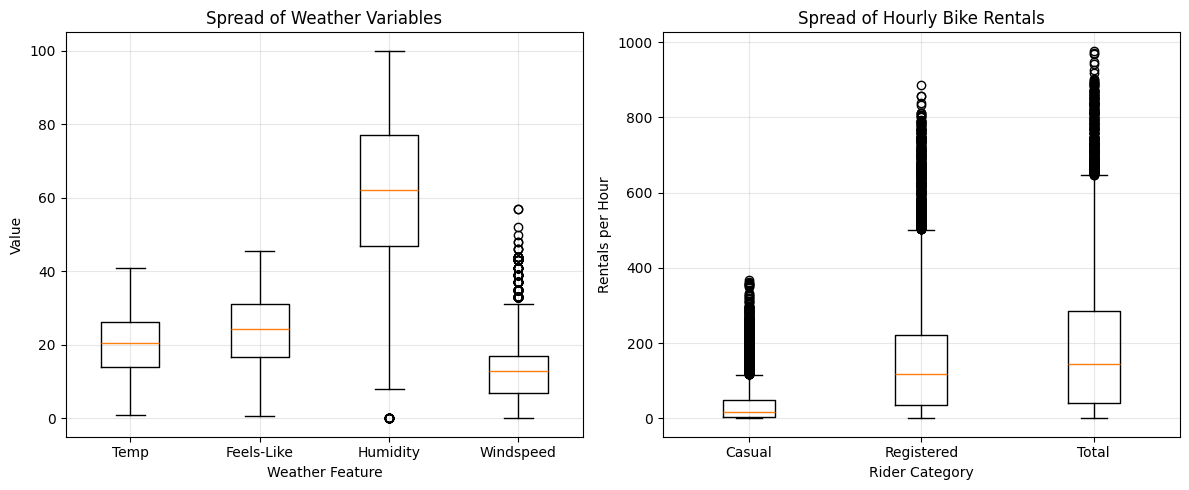

In [8]:
# Box plots for weather metrics and rental counts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

weather_box_cols = ["temp", "atemp", "humidity", "windspeed"]
ax1.boxplot([df_bikes[c] for c in weather_box_cols])
ax1.set_xticklabels(["Temp", "Feels-Like", "Humidity", "Windspeed"])
ax1.set_title("Spread of Weather Variables")
ax1.set_xlabel("Weather Feature")
ax1.set_ylabel("Value")
ax1.grid(True, alpha=0.3)

rental_box_cols = ["casual", "registered", "count"]
ax2.boxplot([df_bikes[c] for c in rental_box_cols])
ax2.set_xticklabels(["Casual", "Registered", "Total"])
ax2.set_title("Spread of Hourly Bike Rentals")
ax2.set_xlabel("Rider Category")
ax2.set_ylabel("Rentals per Hour")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

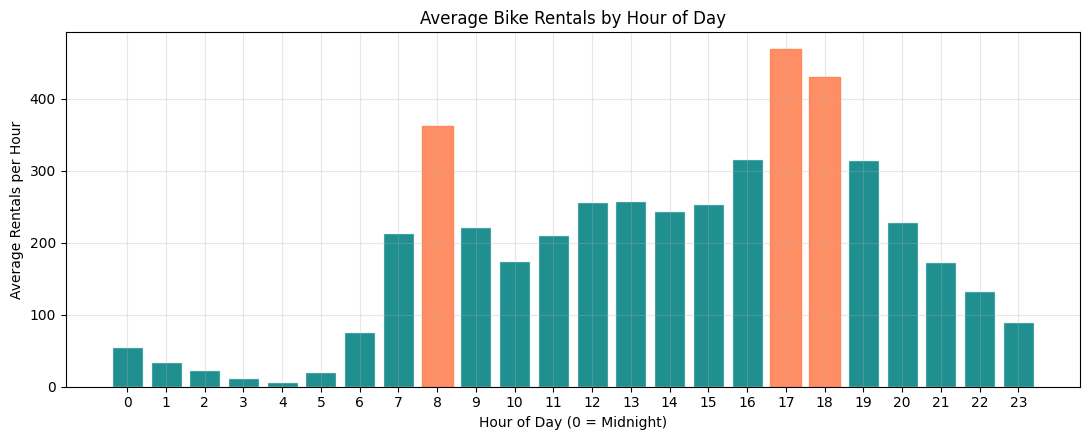

In [9]:
# Bar chart: average rentals by hour of day
hourly_avg = df_bikes.groupby("hour")["count"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(hourly_avg.index, hourly_avg.values, color="teal", edgecolor="white", alpha=0.88)

# Highlight commute peaks at 8 AM and 5–6 PM
for idx in [8, 17, 18]:
    bars[idx].set_color("coral")

ax.set_title("Average Bike Rentals by Hour of Day")
ax.set_xlabel("Hour of Day (0 = Midnight)")
ax.set_ylabel("Average Rentals per Hour")
ax.set_xticks(range(0, 24))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### What the Charts Reveal
* `count` is right-skewed: many quiet overnight hours and a long upper tail.
* Temperature is broad across seasons; humidity is roughly centered near 62%.
* Windspeed has a large spike at 0 (the zero readings noted during cleaning).
* Demand peaks at **8 AM (~363/hr)** and **5–6 PM (~469 and ~431/hr)**.

## Section 6: Categorical Data Analysis

Bar charts and pie charts for season, day of week, weather, day type, and rider share.

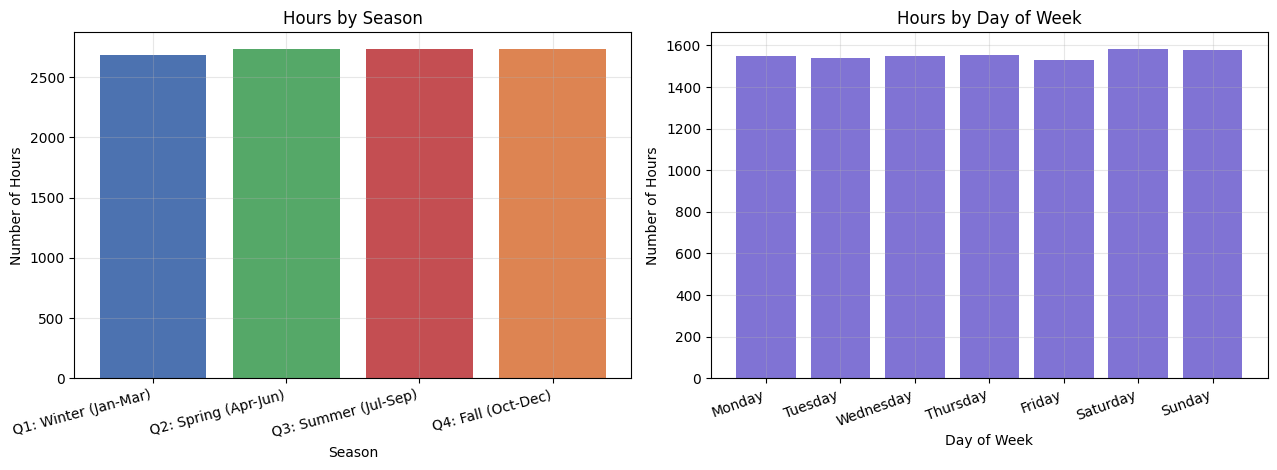

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Order bars with .reindex(order) instead of Categorical
season_counts = df_bikes["season_label"].value_counts().reindex(season_order)
ax1.bar(range(len(season_counts)), season_counts.values,
        color=["#4C72B0", "#55A868", "#C44E52", "#DD8452"])
ax1.set_xticks(range(len(season_counts)))
ax1.set_xticklabels(season_counts.index, rotation=15, ha="right")
ax1.set_title("Hours by Season")
ax1.set_xlabel("Season")
ax1.set_ylabel("Number of Hours")
ax1.grid(True, alpha=0.3)

dow_counts = df_bikes["day_of_week"].value_counts().reindex(weekday_order)
ax2.bar(range(len(dow_counts)), dow_counts.values, color="slateblue", alpha=0.85)
ax2.set_xticks(range(len(dow_counts)))
ax2.set_xticklabels(dow_counts.index, rotation=20, ha="right")
ax2.set_title("Hours by Day of Week")
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Number of Hours")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

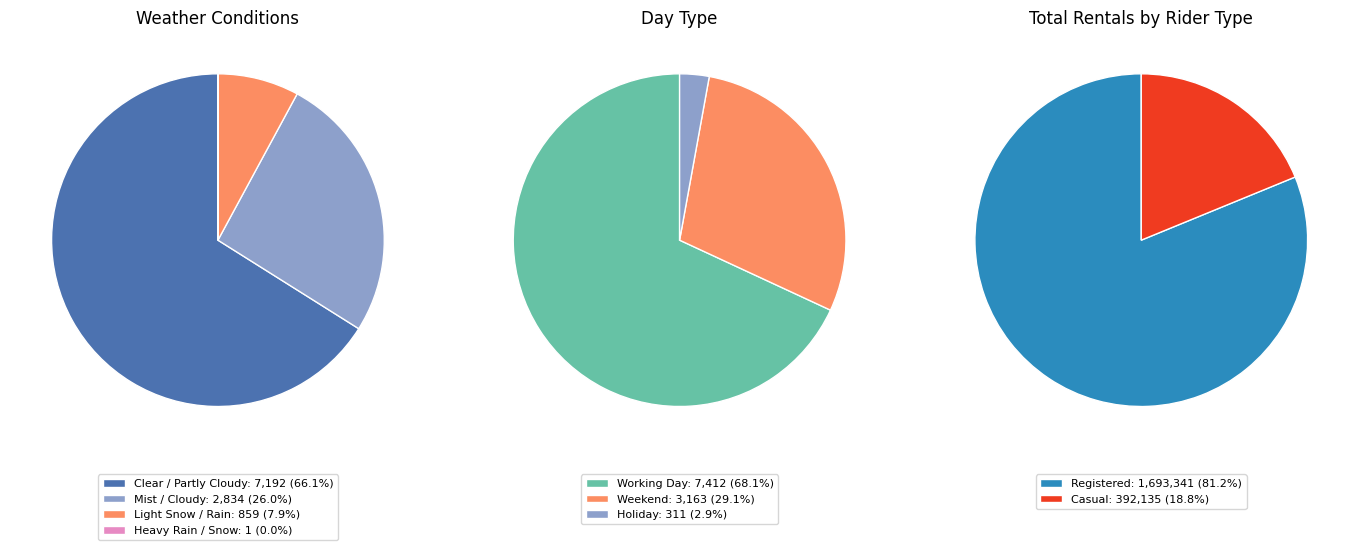

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

pie_configs = [
    ("Weather Conditions",
     df_bikes["weather_label"].value_counts().reindex(weather_order),
     ["#4C72B0", "#8DA0CB", "#FC8D62", "#E78AC3"]),
    ("Day Type",
     df_bikes["day_type"].value_counts().reindex(day_type_order),
     ["#66C2A5", "#FC8D62", "#8DA0CB"]),
    ("Total Rentals by Rider Type",
     pd.Series({"Registered": df_bikes["registered"].sum(),
                "Casual": df_bikes["casual"].sum()}),
     ["#2B8CBE", "#F03B20"]),
]

for ax, (title, series, colors) in zip(axes, pie_configs):
    total = series.sum()
    wedges, _ = ax.pie(series.values, colors=colors, startangle=90,
                       wedgeprops=dict(edgecolor="white"))
    labels = [f"{lbl}: {val:,} ({val / total * 100:.1f}%)"
              for lbl, val in zip(series.index, series.values)]
    ax.set_title(title)
    ax.legend(wedges, labels, loc="upper center", bbox_to_anchor=(0.5, -0.05), fontsize=8)

plt.tight_layout()
plt.show()

### Categorical Takeaways
* Seasons and weekdays are evenly sampled, so later group comparisons are fair.
* Clear weather covers **66.1%** of hours; heavy rain/snow is almost never observed.
* Of all rentals in the dataset, about **81.2%** are registered and **18.8%** are casual.

## Section 7: Grouped Analysis

Group by season, weather, day type, and weekday. For the hour × day-type comparison, loop over each day type and group by hour (Week 11 groupby style) instead of using `pivot_table` / `unstack`.

In [12]:
def grouped_summary(df, group_col, target_col="count"):
    """Grouped count/mean/median/std/min/max for one target column."""
    return (
        df.groupby(group_col)[target_col]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


for g_col in ["season_label", "weather_label", "day_type", "day_of_week"]:
    print(f"\n--- Rentals (count) by {g_col} ---")
    display(grouped_summary(df_bikes, g_col))


--- Rentals (count) by season_label ---


,count,mean,median,std,min,max
season_label,,,,,,
Q1: Winter (Jan-Mar),2686,116.34,78.0,125.27,1,801
Q2: Spring (Apr-Jun),2733,215.25,172.0,192.01,1,873
Q3: Summer (Jul-Sep),2733,234.42,195.0,197.15,1,977
Q4: Fall (Oct-Dec),2734,198.99,161.0,177.62,1,948



--- Rentals (count) by weather_label ---


,count,mean,median,std,min,max
weather_label,,,,,,
Clear / Partly Cloudy,7192,205.24,161.0,187.96,1,977
Heavy Rain / Snow,1,164.00,164.0,NaN,164,164
Light Snow / Rain,859,118.85,71.0,138.58,1,891
Mist / Cloudy,2834,178.96,134.0,168.37,1,890



--- Rentals (count) by day_type ---


,count,mean,median,std,min,max
day_type,,,,,,
Holiday,311,185.88,133.0,168.30,1,712
Weekend,3163,188.77,128.0,174.27,1,783
Working Day,7412,193.01,151.0,184.51,1,977



--- Rentals (count) by day_of_week ---


,count,mean,median,std,min,max
day_of_week,,,,,,
Friday,1529,197.84,167.0,172.52,1,900
Monday,1551,190.39,146.0,180.94,1,968
Saturday,1584,196.67,141.5,180.92,1,783
Sunday,1579,180.84,119.0,167.02,1,757
Thursday,1553,197.30,155.0,187.61,1,901
Tuesday,1539,189.72,146.0,186.72,1,970
Wednesday,1551,188.41,136.0,190.94,1,977


In [13]:
# Multi-column groupby: Season x Day Type
multi_group = (
    df_bikes.groupby(["season_label", "day_type"])[["casual", "registered", "count"]]
    .mean()
    .round(1)
)
print("--- Mean Rentals: Season x Day Type ---")
display(multi_group)

# Hour x Day Type using a for-loop + groupby (instead of pivot_table)
hourly_by_daytype = {}
for day_type in day_type_order:
    subset = df_bikes[df_bikes["day_type"] == day_type]
    hourly_by_daytype[day_type] = subset.groupby("hour")["count"].mean().round(1)

hourly_compare = pd.DataFrame(hourly_by_daytype)
print("\n--- Mean Rentals by Hour x Day Type (selected hours) ---")
display(hourly_compare.loc[[0, 4, 8, 12, 15, 17, 18, 21]])

--- Mean Rentals: Season x Day Type ---


casual  registered  count
season_label         day_type                              
Q1: Winter (Jan-Mar) Holiday         8.1        65.8   73.9
                     Weekend        28.3        80.3  108.6
                     Working Day    10.3       111.1  121.3
Q2: Spring (Apr-Jun) Holiday        38.3       159.5  197.8
                     Weekend        82.4       141.8  224.2
                     Working Day    33.1       178.9  211.9
Q3: Summer (Jul-Sep) Holiday        92.0       145.9  237.8
                     Weekend        81.1       150.8  231.9
                     Working Day    37.8       197.6  235.3
Q4: Fall (Oct-Dec)   Holiday        40.9       169.9  210.8
                     Weekend        49.4       140.4  189.9
                     Working Day    19.0       183.3  202.3


--- Mean Rentals by Hour x Day Type (selected hours) ---


,Working Day,Weekend,Holiday
hour,,,
0,36.7,97.2,66.8
4,5.4,8.7,7.4
8,479.9,100.8,229.0
12,199.3,385.1,318.4
15,198.6,381.7,292.8
17,529.2,336.3,368.0
18,495.5,287.1,344.5
21,184.9,145.5,181.8


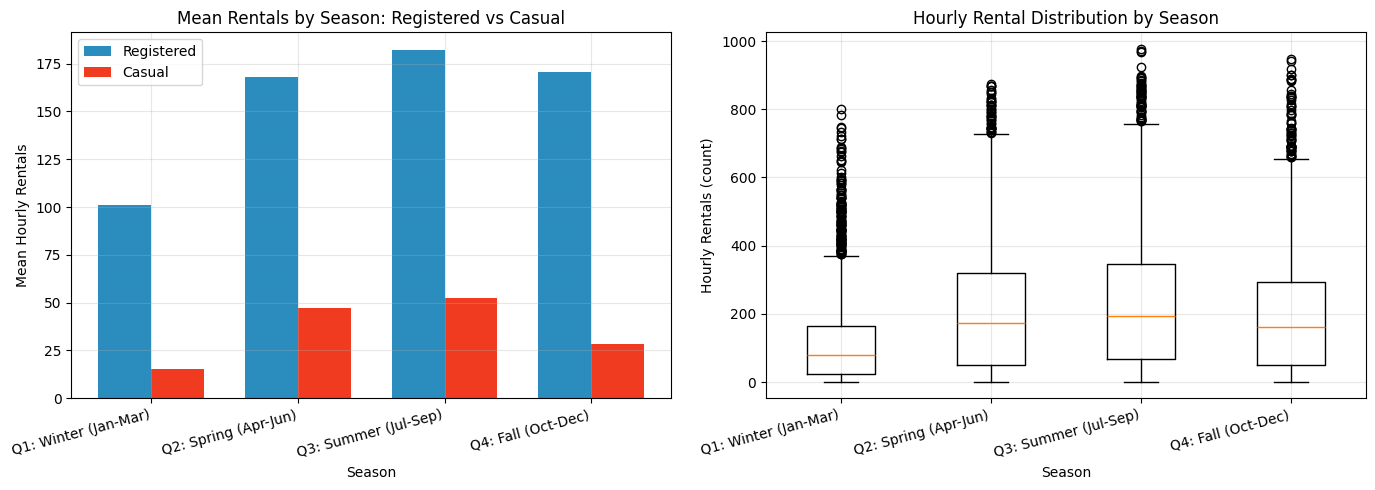

In [14]:
# Grouped bar charts: Registered vs Casual by Season and by Day of Week
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
width = 0.36

season_means = df_bikes.groupby("season_label")[["casual", "registered"]].mean().reindex(season_order)
x = np.arange(len(season_means))
ax1.bar(x - width / 2, season_means["registered"], width, label="Registered", color="#2B8CBE")
ax1.bar(x + width / 2, season_means["casual"], width, label="Casual", color="#F03B20")
ax1.set_xticks(x)
ax1.set_xticklabels(season_means.index, rotation=15, ha="right")
ax1.set_title("Mean Rentals by Season: Registered vs Casual")
ax1.set_xlabel("Season")
ax1.set_ylabel("Mean Hourly Rentals")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Boxplot of count by season
season_arrays = [df_bikes.loc[df_bikes["season_label"] == s, "count"].values for s in season_order]
ax2.boxplot(season_arrays)
ax2.set_xticklabels(season_order, rotation=15, ha="right")
ax2.set_title("Hourly Rental Distribution by Season")
ax2.set_xlabel("Season")
ax2.set_ylabel("Hourly Rentals (count)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

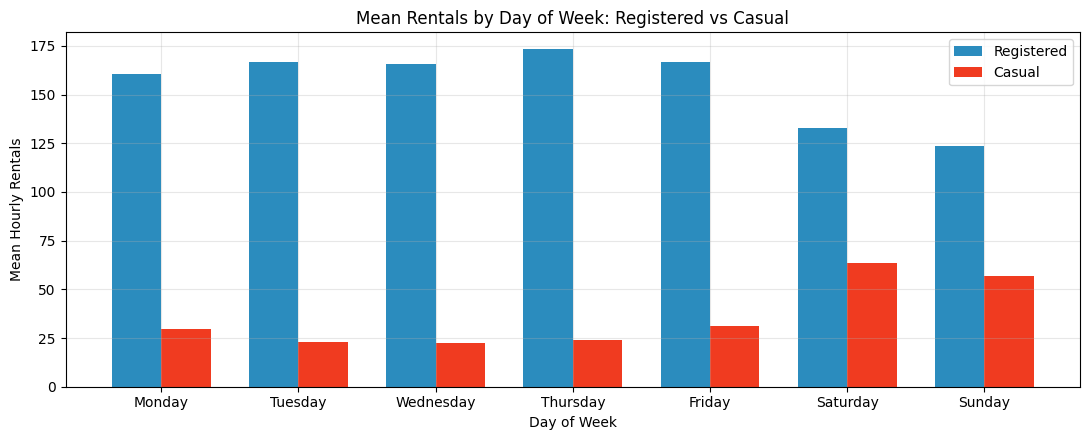

In [15]:
dow_means = df_bikes.groupby("day_of_week")[["casual", "registered"]].mean().reindex(weekday_order)
x_dow = np.arange(len(dow_means))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x_dow - width / 2, dow_means["registered"], width, label="Registered", color="#2B8CBE")
ax.bar(x_dow + width / 2, dow_means["casual"], width, label="Casual", color="#F03B20")
ax.set_xticks(x_dow)
ax.set_xticklabels(dow_means.index)
ax.set_title("Mean Rentals by Day of Week: Registered vs Casual")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Mean Hourly Rentals")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Grouped Analysis Insights
* Demand peaks in **Q3 Summer (234.4/hr)** and **Q2 Spring (215.3/hr)**, and is lowest in **Q1 Winter (116.3/hr)**.
* Clear weather averages **205.2/hr** vs. **118.8/hr** in light rain/snow.
* Total demand is similar across working days and weekends, but the mix flips: registered riders dominate weekdays, while casual rentals more than double on Saturday/Sunday.

## Section 8: New Feature Engineering

Create three useful new columns:
1. **`casual_ratio`** = `casual / count` (share of casual riders)
2. **`temp_diff`** = `atemp - temp` (feels-like minus actual temperature)
3. **`count_vs_2011_pct`** = rentals as a percent of the 2011 mean baseline
4. **`temp_band`** using a small `if/elif` function + `.apply()` (Week 10 style), instead of `pd.cut`

In [16]:
# Ratio and difference features
df_bikes["casual_ratio"] = df_bikes["casual"] / df_bikes["count"]
df_bikes["temp_diff"] = df_bikes["atemp"] - df_bikes["temp"]

# Standardized index relative to 2011 mean (= 100)
base_2011_mean = df_bikes.loc[df_bikes["year"] == 2011, "count"].mean()
df_bikes["count_vs_2011_pct"] = (df_bikes["count"] / base_2011_mean) * 100.0


def assign_temp_band(temp):
    """Bin temperature into comfort bands with if/elif (Week 10 apply style)."""
    if temp < 10:
        return "Cold (<10C)"
    elif temp < 20:
        return "Mild (10-20C)"
    elif temp < 30:
        return "Warm (20-30C)"
    else:
        return "Hot (>30C)"


df_bikes["temp_band"] = df_bikes["temp"].apply(assign_temp_band)
temp_band_order = ["Cold (<10C)", "Mild (10-20C)", "Warm (20-30C)", "Hot (>30C)"]

band_summary = (
    df_bikes.groupby("temp_band")
    .agg(
        hours=("count", "size"),
        mean_count=("count", "mean"),
        mean_casual_ratio=("casual_ratio", "mean"),
        mean_index_vs_2011=("count_vs_2011_pct", "mean"),
    )
    .reindex(temp_band_order)
    .round(3)
)
print(f"2011 baseline mean hourly rentals: {base_2011_mean:.2f}")
display(band_summary)

daytype_ratio = (
    df_bikes.groupby("day_type")[["casual_ratio", "count_vs_2011_pct"]]
    .mean()
    .reindex(day_type_order)
    .round(3)
)
display(daytype_ratio)

2011 baseline mean hourly rentals: 144.22


,hours,mean_count,mean_casual_ratio,mean_index_vs_2011
temp_band,,,,
Cold (<10C),1259,73.186,0.071,50.745
Mild (10-20C),4049,150.465,0.139,104.328
Warm (20-30C),4334,223.411,0.205,154.907
Hot (>30C),1244,334.274,0.258,231.775


,casual_ratio,count_vs_2011_pct
day_type,,
Working Day,0.136,133.828
Weekend,0.248,130.884
Holiday,0.218,128.882


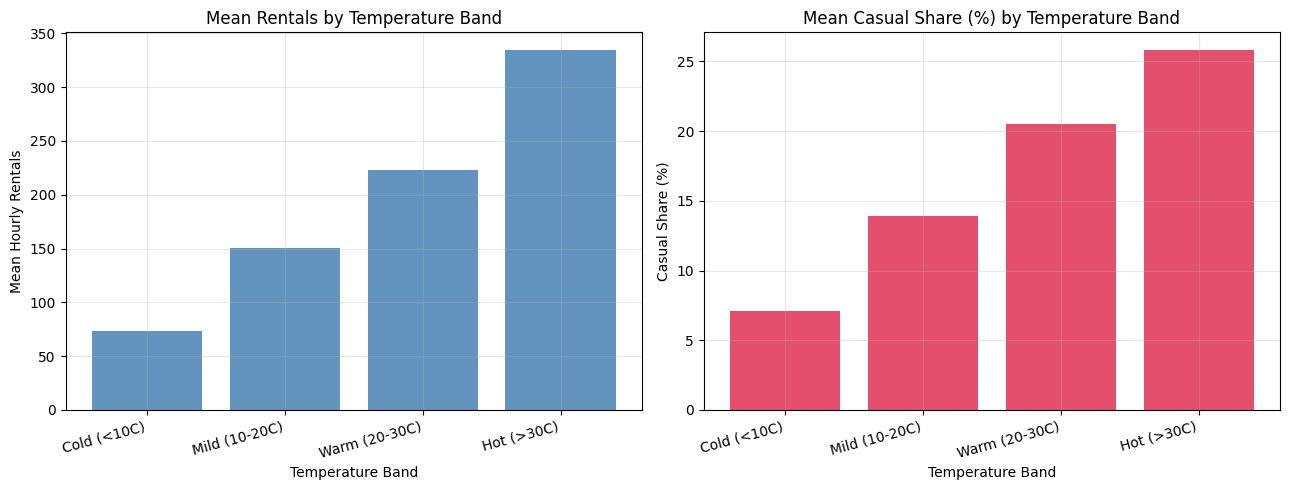

In [17]:
# Side-by-side charts instead of twinx:
# Left = mean rentals by temp band; Right = casual share by temp band
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar(range(len(band_summary)), band_summary["mean_count"], color="steelblue", alpha=0.85)
ax1.set_xticks(range(len(band_summary)))
ax1.set_xticklabels(band_summary.index, rotation=15, ha="right")
ax1.set_title("Mean Rentals by Temperature Band")
ax1.set_xlabel("Temperature Band")
ax1.set_ylabel("Mean Hourly Rentals")
ax1.grid(True, alpha=0.3)

ax2.bar(range(len(band_summary)), band_summary["mean_casual_ratio"] * 100,
        color="crimson", alpha=0.75)
ax2.set_xticks(range(len(band_summary)))
ax2.set_xticklabels(band_summary.index, rotation=15, ha="right")
ax2.set_title("Mean Casual Share (%) by Temperature Band")
ax2.set_xlabel("Temperature Band")
ax2.set_ylabel("Casual Share (%)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

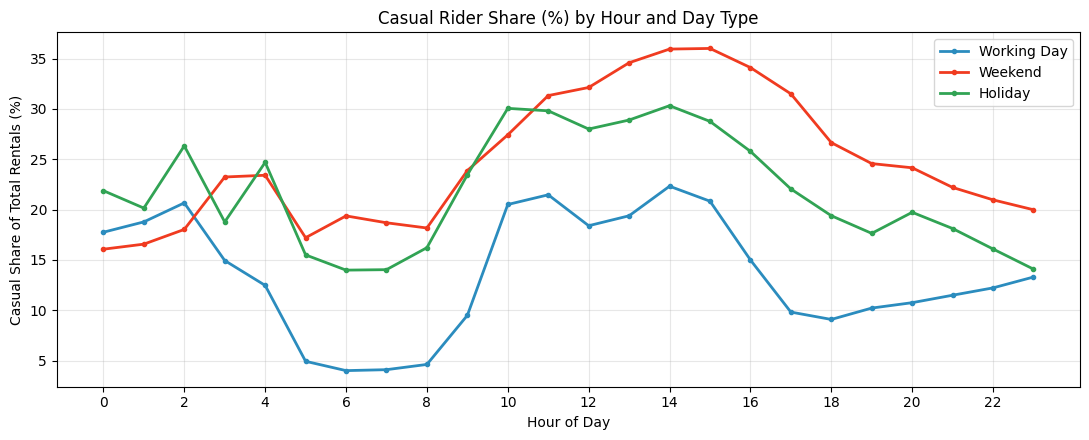

In [18]:
# Hourly casual share by day type (loop + groupby instead of unstack)
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = {"Working Day": "#2B8CBE", "Weekend": "#F03B20", "Holiday": "#31A354"}

for day_type in day_type_order:
    subset = df_bikes[df_bikes["day_type"] == day_type]
    hourly_ratio = subset.groupby("hour")["casual_ratio"].mean() * 100
    ax.plot(hourly_ratio.index, hourly_ratio.values, marker="o", markersize=3,
            linewidth=2, label=day_type, color=colors[day_type])

ax.set_title("Casual Rider Share (%) by Hour and Day Type")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Casual Share of Total Rentals (%)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Feature Engineering Takeaways
* Moving from Cold to Hot more than quadruples mean hourly rentals (**73.2 → 334.3**) and raises casual share from about **7% to 26%**.
* Casual share peaks in the midday/afternoon, especially on weekends (**~31–36%**), while working-day midday share stays lower (**~15–22%**).

## Section 9: Trends Over Time

Monthly averages, daily totals, standardized (z-score) monthly series so count/temp/humidity can be compared on one scale, and weekday vs weekend hourly curves.

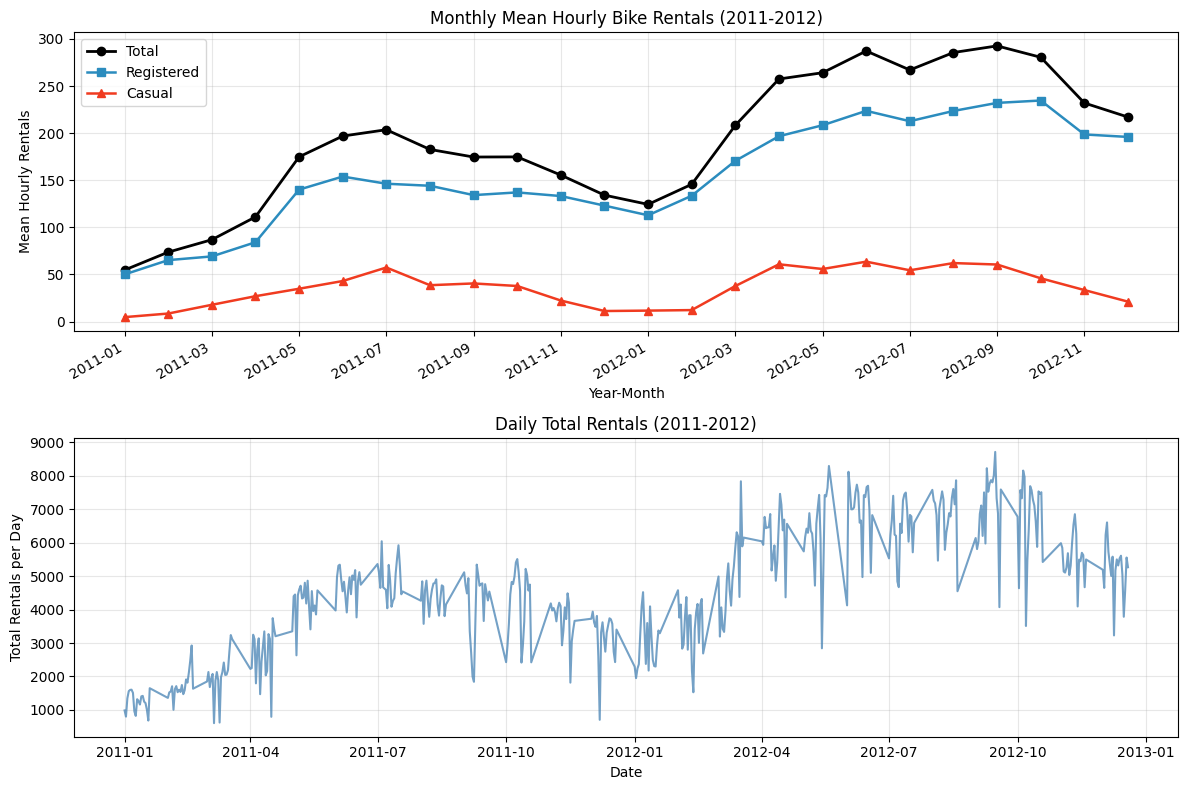

In [19]:
# Monthly averages using the YYYY-MM string column
monthly_df = (
    df_bikes.groupby("year_month")
    .agg(
        count=("count", "mean"),
        registered=("registered", "mean"),
        casual=("casual", "mean"),
        temp=("temp", "mean"),
        humidity=("humidity", "mean"),
    )
    .reset_index()
)

# Daily totals (plot directly instead of rolling mean)
daily_df = (
    df_bikes.groupby(df_bikes["datetime"].dt.date)
    .agg(daily_count=("count", "sum"), mean_temp=("temp", "mean"))
    .reset_index()
)
daily_df = daily_df.rename(columns={"datetime": "date"})
daily_df["date"] = pd.to_datetime(daily_df["date"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
x_m = np.arange(len(monthly_df))

ax1.plot(x_m, monthly_df["count"], marker="o", linewidth=2, color="black", label="Total")
ax1.plot(x_m, monthly_df["registered"], marker="s", linewidth=1.8, color="#2B8CBE", label="Registered")
ax1.plot(x_m, monthly_df["casual"], marker="^", linewidth=1.8, color="#F03B20", label="Casual")
ax1.set_title("Monthly Mean Hourly Bike Rentals (2011-2012)")
ax1.set_xlabel("Year-Month")
ax1.set_ylabel("Mean Hourly Rentals")
ax1.set_xticks(x_m[::2])
ax1.set_xticklabels(monthly_df["year_month"].iloc[::2], rotation=30, ha="right")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(daily_df["date"], daily_df["daily_count"], color="steelblue", alpha=0.75)
ax2.set_title("Daily Total Rentals (2011-2012)")
ax2.set_xlabel("Date")
ax2.set_ylabel("Total Rentals per Day")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

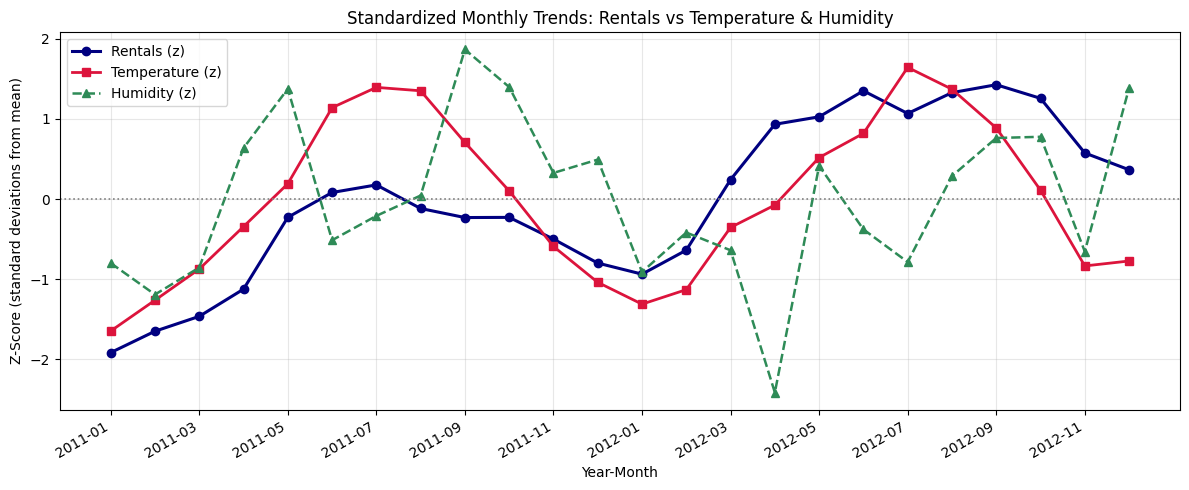

In [20]:
# Standardized monthly values so different units can share one axis
for col in ["count", "temp", "humidity"]:
    monthly_df[col + "_z"] = (monthly_df[col] - monthly_df[col].mean()) / monthly_df[col].std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x_m, monthly_df["count_z"], marker="o", linewidth=2.2, color="navy", label="Rentals (z)")
ax.plot(x_m, monthly_df["temp_z"], marker="s", linewidth=2.0, color="crimson", label="Temperature (z)")
ax.plot(x_m, monthly_df["humidity_z"], marker="^", linewidth=1.8, linestyle="--",
        color="seagreen", label="Humidity (z)")
ax.axhline(0, color="gray", linestyle=":", linewidth=1.2)
ax.set_title("Standardized Monthly Trends: Rentals vs Temperature & Humidity")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Z-Score (standard deviations from mean)")
ax.set_xticks(x_m[::2])
ax.set_xticklabels(monthly_df["year_month"].iloc[::2], rotation=30, ha="right")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

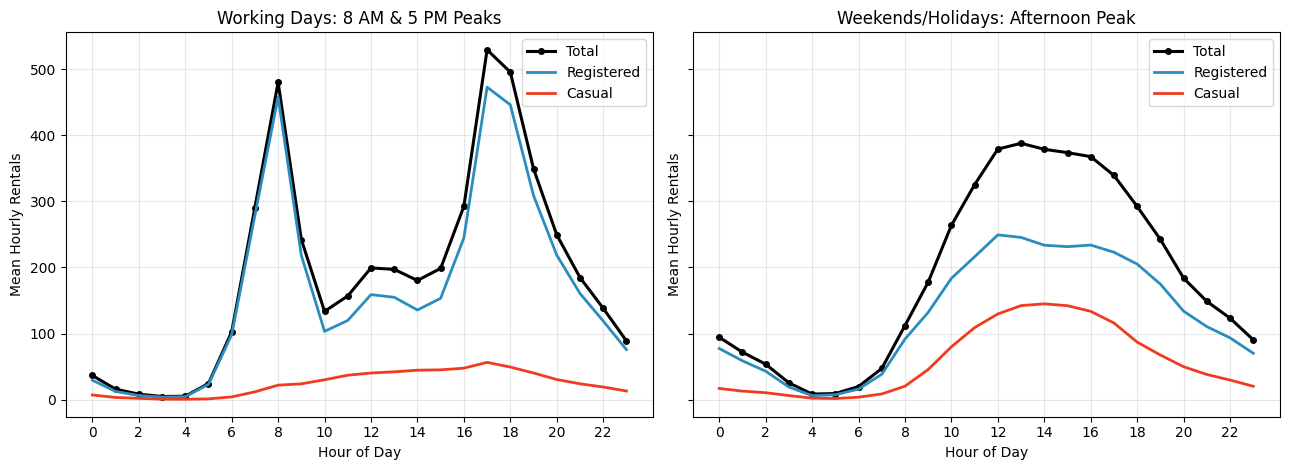

In [21]:
# Working-day vs weekend/holiday hourly profiles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, wd_val, title in [
    (ax1, 1, "Working Days: 8 AM & 5 PM Peaks"),
    (ax2, 0, "Weekends/Holidays: Afternoon Peak"),
]:
    sub = df_bikes[df_bikes["workingday"] == wd_val]
    hourly = sub.groupby("hour")[["count", "registered", "casual"]].mean()
    ax.plot(hourly.index, hourly["count"], marker="o", markersize=4, linewidth=2.2,
            color="black", label="Total")
    ax.plot(hourly.index, hourly["registered"], linewidth=2.0, color="#2B8CBE", label="Registered")
    ax.plot(hourly.index, hourly["casual"], linewidth=2.0, color="#F03B20", label="Casual")
    ax.set_title(title)
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Mean Hourly Rentals")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Time-Trend Insights
* Mean hourly rentals rose from **144.2 in 2011** to **238.6 in 2012** (**+65.4%**).
* On the z-score chart, rentals move closely with seasonal temperature.
* Weekdays show sharp commute peaks; weekends show one smoother afternoon peak.

## Section 10: Variable Relationships

Compute correlation and covariance, show the correlation table, take a random sample of 1,000 rows (sampling from Week 11), and make scatter plots.

In [22]:
rel_cols = [
    "temp", "atemp", "humidity", "windspeed", "weather", "hour",
    "workingday", "year", "casual", "registered", "count", "casual_ratio",
]

corr_matrix = df_bikes[rel_cols].corr()
cov_matrix = df_bikes[["temp", "humidity", "windspeed", "casual", "registered", "count"]].cov().round(2)

print("--- Covariance Matrix ---")
display(cov_matrix)
print("\n--- Correlation with count ---")
display(corr_matrix["count"].sort_values(ascending=False).round(3).to_frame("corr_with_count"))

print("\n--- Full Correlation Matrix ---")
display(corr_matrix.round(2))

--- Covariance Matrix ---


,temp,humidity,windspeed,casual,registered,count
temp,60.71,-9.74,-1.14,181.83,374.91,556.73
humidity,-9.74,370.37,-50.06,-334.78,-771.62,-1106.40
windspeed,-1.14,-50.06,66.66,37.64,112.28,149.92
casual,181.83,-334.78,37.64,2496.05,3752.24,6248.29
registered,374.91,-771.62,112.28,3752.24,22812.79,26565.03
count,556.73,-1106.40,149.92,6248.29,26565.03,32813.31



--- Correlation with count ---


,corr_with_count
count,1.000
registered,0.971
casual,0.690
hour,0.401
temp,0.394
atemp,0.390
year,0.260
casual_ratio,0.131
windspeed,0.101
workingday,0.012



--- Full Correlation Matrix ---


,temp,atemp,humidity,windspeed,weather,hour,workingday,year,casual,registered,count,casual_ratio
temp,1.00,0.98,-0.06,-0.02,-0.06,0.15,0.03,0.06,0.47,0.32,0.39,0.42
atemp,0.98,1.00,-0.04,-0.06,-0.06,0.14,0.02,0.06,0.46,0.31,0.39,0.42
humidity,-0.06,-0.04,1.00,-0.32,0.41,-0.28,-0.01,-0.08,-0.35,-0.27,-0.32,-0.15
windspeed,-0.02,-0.06,-0.32,1.00,0.01,0.15,0.01,-0.02,0.09,0.09,0.10,0.02
weather,-0.06,-0.06,0.41,0.01,1.00,-0.02,0.03,-0.01,-0.14,-0.11,-0.13,-0.11
hour,0.15,0.14,-0.28,0.15,-0.02,1.00,0.00,-0.00,0.30,0.38,0.40,0.04
workingday,0.03,0.02,-0.01,0.01,0.03,0.00,1.00,-0.00,-0.32,0.12,0.01,-0.37
year,0.06,0.06,-0.08,-0.02,-0.01,-0.00,-0.00,1.00,0.15,0.26,0.26,-0.07
casual,0.47,0.46,-0.35,0.09,-0.14,0.30,-0.32,0.15,1.00,0.50,0.69,0.57
registered,0.32,0.31,-0.27,0.09,-0.11,0.38,0.12,0.26,0.50,1.00,0.97,-0.03


In [23]:
# Random sample of n = 1,000 (Week 11 sampling concept)
df_sample = df_bikes.sample(n=1000, random_state=42)

sample_comparison = pd.DataFrame({
    "Full Mean (N=10886)": df_bikes[["temp", "humidity", "windspeed", "count", "casual_ratio"]].mean(),
    "Sample Mean (n=1000)": df_sample[["temp", "humidity", "windspeed", "count", "casual_ratio"]].mean(),
    "Full Std": df_bikes[["temp", "humidity", "windspeed", "count", "casual_ratio"]].std(),
    "Sample Std": df_sample[["temp", "humidity", "windspeed", "count", "casual_ratio"]].std(),
}).round(3)

print("--- Full Dataset vs Random Sample ---")
display(sample_comparison)
print(
    "Sample corr(temp, count):",
    round(df_sample["temp"].corr(df_sample["count"]), 3),
    "| Full corr:",
    round(df_bikes["temp"].corr(df_bikes["count"]), 3),
)

--- Full Dataset vs Random Sample ---


,Full Mean (N=10886),Sample Mean (n=1000),Full Std,Sample Std
temp,20.231,20.092,7.792,7.813
humidity,61.886,62.189,19.245,18.785
windspeed,12.799,12.882,8.165,8.056
count,191.574,191.126,181.144,182.088
casual_ratio,0.171,0.171,0.137,0.137


Sample corr(temp, count): 0.4 | Full corr: 0.394


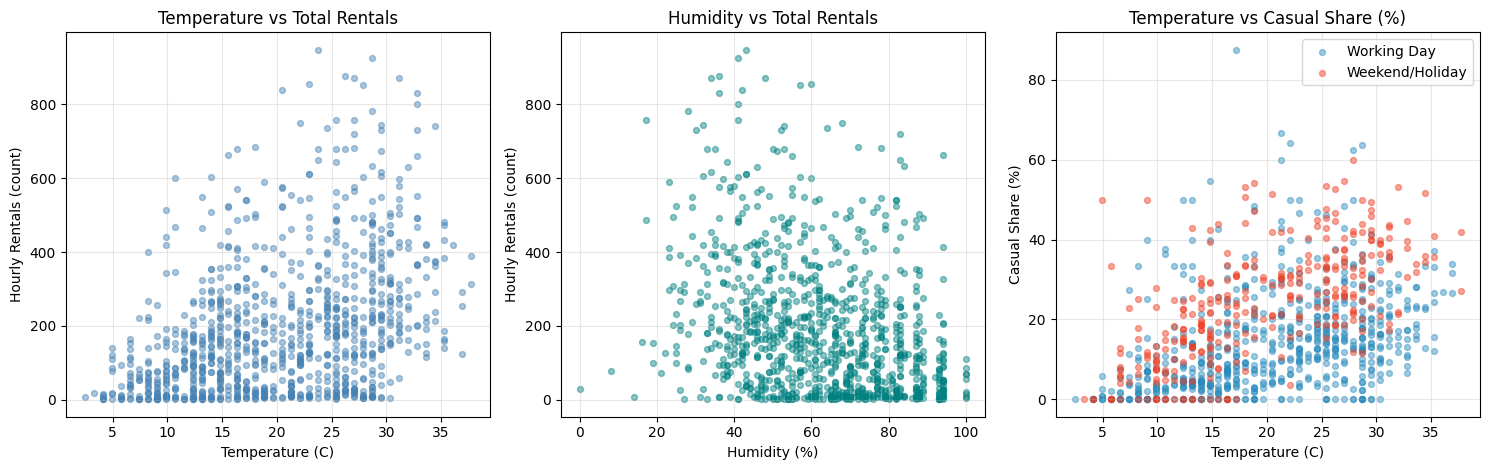

In [24]:
# Scatter plots from the sample so points stay readable
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].scatter(df_sample["temp"], df_sample["count"], alpha=0.45, s=18, color="steelblue")
axes[0].set_title("Temperature vs Total Rentals")
axes[0].set_xlabel("Temperature (C)")
axes[0].set_ylabel("Hourly Rentals (count)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(df_sample["humidity"], df_sample["count"], alpha=0.45, s=18, color="teal")
axes[1].set_title("Humidity vs Total Rentals")
axes[1].set_xlabel("Humidity (%)")
axes[1].set_ylabel("Hourly Rentals (count)")
axes[1].grid(True, alpha=0.3)

for wd, color, label in [(1, "#2B8CBE", "Working Day"), (0, "#F03B20", "Weekend/Holiday")]:
    sub = df_sample[df_sample["workingday"] == wd]
    axes[2].scatter(sub["temp"], sub["casual_ratio"] * 100, alpha=0.45, s=18, color=color, label=label)
axes[2].set_title("Temperature vs Casual Share (%)")
axes[2].set_xlabel("Temperature (C)")
axes[2].set_ylabel("Casual Share (%)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Relationship Takeaways
* Strongest independent correlates of `count`: `hour` (**0.401**), `temp` (**0.394**), `atemp` (**0.390**); humidity is negative (**-0.317**).
* `temp` and `atemp` are nearly identical (**r = 0.985**), so only one should be used in regression.
* The n = 1,000 sample closely matches full-data means and the temp–count correlation.

## Section 11: Hypothesis

* **H1:** Higher temperature (`temp`) is positively associated with higher hourly rentals (`count`), because warmer weather makes outdoor cycling more comfortable.
* **H2:** A multiple linear regression that also includes humidity, windspeed, hour, workingday, and year will explain more variance in `count` than temperature alone.

## Section 12: Linear Regression with `sklearn`

Fit a simple model (`temp → count`) and a multiple model with six predictors.

### Something New (Requirement 13)
Weeks 1–11 covered pandas plotting and descriptive analysis, but not a full train/test regression evaluation workflow. Here I use **`train_test_split`**, evaluate with **`r2_score` / RMSE / MAE**, and add a **residual diagnostic plot** (actual − predicted vs. predicted). These go beyond class homework while still using the required `LinearRegression`.

In [25]:
def evaluate_regression(model, X_train, X_test, y_train, y_test, model_name):
    """Fit a model and return test predictions plus train/test metrics."""
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    metrics = {
        "Model": model_name,
        "Train R^2": round(r2_score(y_train, train_pred), 4),
        "Test R^2": round(r2_score(y_test, test_pred), 4),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, test_pred)), 2),
        "Test MAE": round(mean_absolute_error(y_test, test_pred), 2),
    }
    return model, test_pred, metrics


y = df_bikes["count"]
multi_features = ["temp", "humidity", "windspeed", "hour", "workingday", "year"]

X_train_all, X_test_all, y_train, y_test = train_test_split(
    df_bikes[multi_features], y, test_size=0.20, random_state=42
)

simple_model, y_pred_simple, metrics_simple = evaluate_regression(
    LinearRegression(),
    X_train_all[["temp"]],
    X_test_all[["temp"]],
    y_train,
    y_test,
    "Simple LR (temp only)",
)

multi_model, y_pred_multi, metrics_multi = evaluate_regression(
    LinearRegression(),
    X_train_all,
    X_test_all,
    y_train,
    y_test,
    "Multiple LR (6 features)",
)

print(
    f"Simple LR: count = {simple_model.intercept_:.2f} + "
    f"{simple_model.coef_[0]:.2f} * temp"
)
display(pd.DataFrame([metrics_simple, metrics_multi]).set_index("Model"))

coef_df = pd.DataFrame({
    "Feature": multi_features,
    "Coefficient": np.round(multi_model.coef_, 3),
})
print(f"\nMultiple LR intercept: {multi_model.intercept_:.2f}")
display(coef_df)

Simple LR: count = 7.86 + 9.06 * temp


,Train R^2,Test R^2,Test RMSE,Test MAE
Model,,,,
Simple LR (temp only),0.1521,0.1693,165.59,125.15
Multiple LR (6 features),0.3666,0.3785,143.22,106.29



Multiple LR intercept: -164798.04


,Feature,Coefficient
0,temp,7.420
1,humidity,-1.820
2,windspeed,0.031
3,hour,7.911
4,workingday,1.050
5,year,81.958


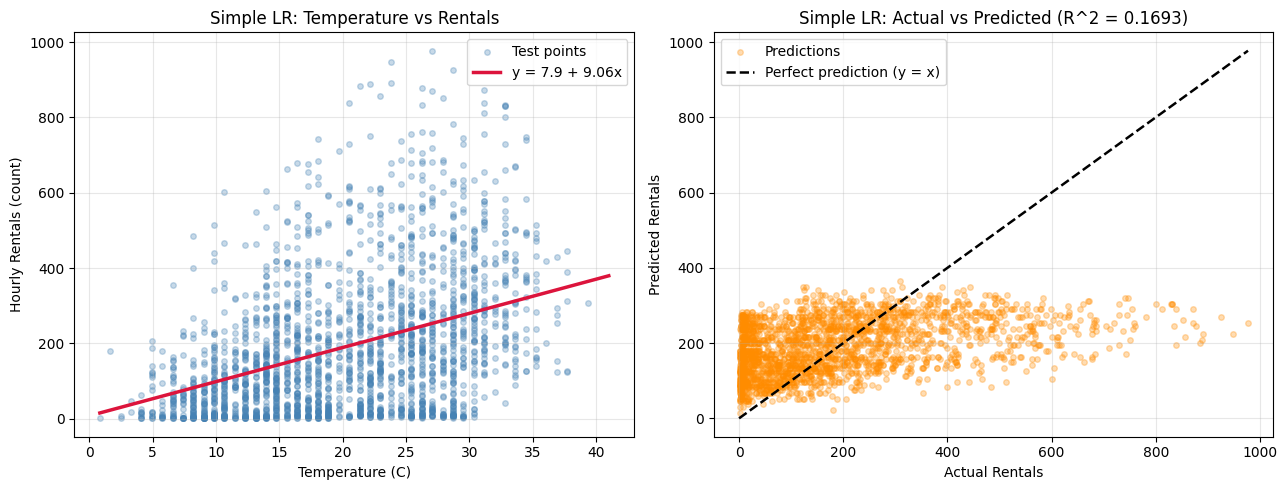

In [26]:
# Simple LR: regression line + actual vs predicted
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

x_vals = np.linspace(df_bikes["temp"].min(), df_bikes["temp"].max(), 100).reshape(-1, 1)
y_line = simple_model.predict(pd.DataFrame(x_vals, columns=["temp"]))

ax1.scatter(X_test_all["temp"], y_test, alpha=0.3, s=16, color="steelblue", label="Test points")
ax1.plot(
    x_vals, y_line, color="crimson", linewidth=2.5,
    label=f"y = {simple_model.intercept_:.1f} + {simple_model.coef_[0]:.2f}x",
)
ax1.set_title("Simple LR: Temperature vs Rentals")
ax1.set_xlabel("Temperature (C)")
ax1.set_ylabel("Hourly Rentals (count)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.scatter(y_test, y_pred_simple, alpha=0.3, s=16, color="darkorange", label="Predictions")
lims = [0, max(y_test.max(), y_pred_simple.max())]
ax2.plot(lims, lims, "k--", linewidth=1.8, label="Perfect prediction (y = x)")
ax2.set_title(f"Simple LR: Actual vs Predicted (R^2 = {metrics_simple['Test R^2']})")
ax2.set_xlabel("Actual Rentals")
ax2.set_ylabel("Predicted Rentals")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

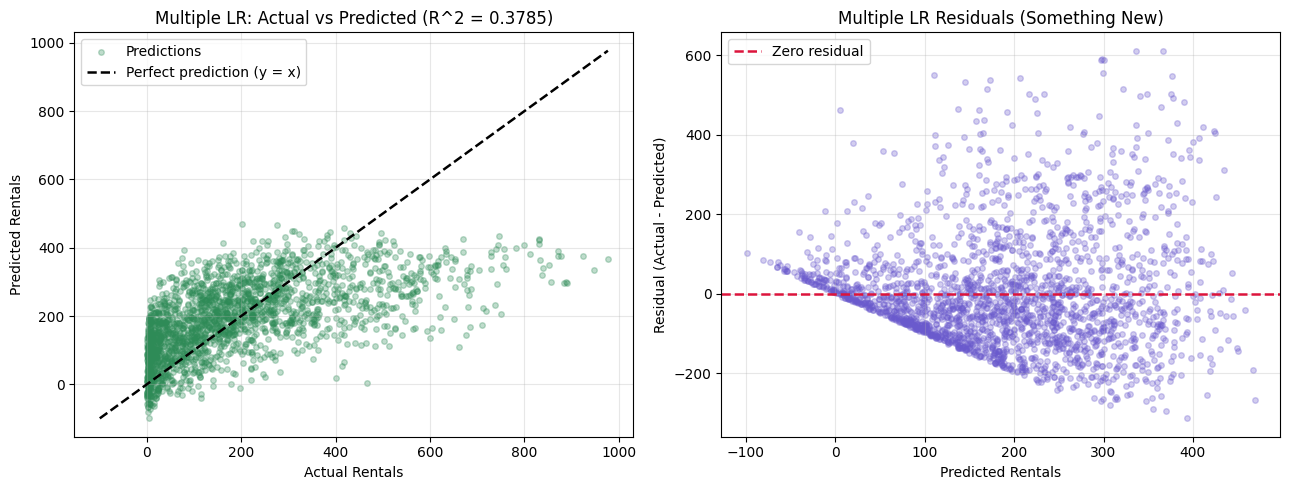

In [27]:
# Multiple LR: actual vs predicted + residual diagnostic (Something New)
residuals_multi = y_test - y_pred_multi

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(y_test, y_pred_multi, alpha=0.3, s=16, color="seagreen", label="Predictions")
lims_m = [min(0, y_pred_multi.min()), y_test.max()]
ax1.plot(lims_m, lims_m, "k--", linewidth=1.8, label="Perfect prediction (y = x)")
ax1.set_title(f"Multiple LR: Actual vs Predicted (R^2 = {metrics_multi['Test R^2']})")
ax1.set_xlabel("Actual Rentals")
ax1.set_ylabel("Predicted Rentals")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.scatter(y_pred_multi, residuals_multi, alpha=0.3, s=16, color="slateblue")
ax2.axhline(0, color="crimson", linestyle="--", linewidth=1.8, label="Zero residual")
ax2.set_title("Multiple LR Residuals (Something New)")
ax2.set_xlabel("Predicted Rentals")
ax2.set_ylabel("Residual (Actual - Predicted)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Regression Discussion
1. **What the results suggest:** Temperature alone has slope **+9.06 rentals/°C**, supporting H1. In the multiple model, temperature (+7.42), hour (+7.91), and year (+81.96) raise demand, while humidity (−1.82) lowers it. Test $R^2$ rises from **0.169** to **0.379**, supporting H2.
2. **How good is the fit?** Temperature alone is only a modest explanation. The six-feature model is better, but most variance is still unexplained.
3. **Limitations:** Hourly demand is bimodal (8 AM and 5 PM peaks), so a straight line on numeric `hour` cannot capture rush-hour shape. Residuals show that clearly. Interactions (hour × workingday) and non-linear models would help.

## Section 13: Reflection / Conclusion

### Key Findings
* Rentals peak in summer/spring and are lowest in winter; demand grew **+65.4%** from 2011 to 2012.
* Clear weather and warmer temperature bands are linked to much higher demand.
* Registered riders drive weekday commute peaks; casual riders rise on weekends.
* Linear regression confirms a positive temperature effect and better fit when calendar/weather features are added, but linear models miss rush-hour non-linearity.

### Something New Beyond Weeks 1–11
Most of this notebook uses course techniques (`describe`, `groupby`, `map`, `apply`, histograms/box/bar/pie/line/scatter plots, and sampling). The beyond-homework skills are:
1. **`train_test_split` + `r2_score` / RMSE / MAE** for fair out-of-sample evaluation of `LinearRegression`
2. **Residual diagnostic plotting** to check where the multiple linear model fails

### Limitations & Future Work
* Only days 1–19 of each month are present.
* Many zero windspeed readings and almost no heavy-rain observations.
* Future models could encode hour as categories or use non-linear methods to capture commute peaks.